In [ ]:
from pathlib import Path
import sys
import warnings

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()

while PROJECT_ROOT.name != "team4_placeholder":
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError(
            "Project root was not found."
        )

    PROJECT_ROOT = PROJECT_ROOT.parent

INPUT_PATH = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "urls"
    / "corrected_preprocessed_urls.csv"
)

ARTIFACTS_DIRECTORY = (
    PROJECT_ROOT
    / "ml"
    / "artifacts"
)

print(f"Project root: {PROJECT_ROOT}")
print(f"Input file: {INPUT_PATH}")
print(f"File exists: {INPUT_PATH.exists()}")

Project root: c:\SafeFlowAI\team4_placeholder
Input file: c:\SafeFlowAI\team4_placeholder\data\raw\urls\corrected_preprocessed_urls.csv
File exists: True


In [15]:
if not INPUT_PATH.exists():
    raise FileNotFoundError(
        f"Input file does not exist: {INPUT_PATH}"
    )

df = pd.read_csv(
    INPUT_PATH,
    encoding="utf-8"
)

df.columns = (
    df.columns
    .astype(str)
    .str.strip()
)

print(f"Dataset shape: {df.shape}")
print("Dataset columns:")
print(df.columns.tolist())

Dataset shape: (822010, 19)
Dataset columns:
['url', 'url_length', 'num_digits', 'digit_ratio', 'special_char_ratio', 'num_hyphens', 'num_underscores', 'num_slashes', 'num_dots', 'num_question_marks', 'num_equals', 'num_at_symbols', 'num_percent', 'num_hashes', 'num_ampersands', 'num_subdomains', 'is_https', 'has_suspicious_word', 'status']


In [16]:
display(df.head())

print("Dataset information:")
df.info()

print("\nMissing values:")
display(df.isna().sum())

print(
    "\nDuplicated rows:",
    df.duplicated().sum()
)

print("\nTarget distribution:")
print(df["status"].value_counts(dropna=False))

,url,url_length,num_digits,digit_ratio,special_char_ratio,num_hyphens,num_underscores,num_slashes,num_dots,num_question_marks,num_equals,num_at_symbols,num_percent,num_hashes,num_ampersands,num_subdomains,is_https,has_suspicious_word,status
0,0000111servicehelpdesk.godaddysites.com,39,7,0.179487,0.051282,0,0,0,2,0,0,0,0,0,0,0,0,False,0
1,000011accesswebform.godaddysites.com,36,6,0.166667,0.055556,0,0,0,2,0,0,0,0,0,0,0,0,False,0
2,00003.online,12,5,0.416667,0.083333,0,0,0,1,0,0,0,0,0,0,0,0,False,0
3,0009servicedeskowa.godaddysites.com,35,4,0.114286,0.057143,0,0,0,2,0,0,0,0,0,0,0,0,False,0
4,000n38p.wcomhost.com,20,5,0.250000,0.100000,0,0,0,2,0,0,0,0,0,0,0,0,False,0


Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 822010 entries, 0 to 822009
Data columns (total 19 columns):
 #   Column               Non-Null Count   Dtype  
---  ------               --------------   -----  
 0   url                  822010 non-null  str    
 1   url_length           822010 non-null  int64  
 2   num_digits           822010 non-null  int64  
 3   digit_ratio          822010 non-null  float64
 4   special_char_ratio   822010 non-null  float64
 5   num_hyphens          822010 non-null  int64  
 6   num_underscores      822010 non-null  int64  
 7   num_slashes          822010 non-null  int64  
 8   num_dots             822010 non-null  int64  
 9   num_question_marks   822010 non-null  int64  
 10  num_equals           822010 non-null  int64  
 11  num_at_symbols       822010 non-null  int64  
 12  num_percent          822010 non-null  int64  
 13  num_hashes           822010 non-null  int64  
 14  num_ampersands       822010 non-null  int64  
 15  num_sub

url                    0
url_length             0
num_digits             0
digit_ratio            0
special_char_ratio     0
num_hyphens            0
num_underscores        0
num_slashes            0
num_dots               0
num_question_marks     0
num_equals             0
num_at_symbols         0
num_percent            0
num_hashes             0
num_ampersands         0
num_subdomains         0
is_https               0
has_suspicious_word    0
status                 0
dtype: int64


Duplicated rows: 13968

Target distribution:
status
1    427028
0    394982
Name: count, dtype: int64


In [17]:
URL_COLUMN = "url"
TARGET_COLUMN = "status"

FEATURE_COLUMNS = [
    "url_length",
    "num_digits",
    "digit_ratio",
    "special_char_ratio",
    "num_hyphens",
    "num_underscores",
    "num_slashes",
    "num_dots",
    "num_question_marks",
    "num_equals",
    "num_at_symbols",
    "num_percent",
    "num_hashes",
    "num_ampersands",
    "num_subdomains",
    "is_https",
    "has_suspicious_word",
]

required_columns = (
    [URL_COLUMN, TARGET_COLUMN]
    + FEATURE_COLUMNS
)

missing_columns = [
    column
    for column in required_columns
    if column not in df.columns
]

if missing_columns:
    raise ValueError(
        f"Missing columns: {missing_columns}"
    )

print("All required columns are available.")

All required columns are available.


In [18]:
df = df.copy()

df[URL_COLUMN] = (
    df[URL_COLUMN]
    .fillna("")
    .astype(str)
    .str.strip()
)

df = df[
    df[URL_COLUMN] != ""
].copy()

df = df.drop_duplicates(
    subset=[URL_COLUMN]
).copy()

df[TARGET_COLUMN] = pd.to_numeric(
    df[TARGET_COLUMN],
    errors="coerce"
)

df = df.dropna(
    subset=[TARGET_COLUMN]
).copy()

df[TARGET_COLUMN] = (
    df[TARGET_COLUMN]
    .astype(int)
)

print(
    f"Rows after cleaning: {len(df)}"
)

print("\nTarget distribution after cleaning:")
print(df[TARGET_COLUMN].value_counts())

Rows after cleaning: 808039

Target distribution after cleaning:
status
1    427028
0    381011
Name: count, dtype: int64


In [19]:
unique_labels = sorted(
    df[TARGET_COLUMN].unique()
)

print("Target labels:", unique_labels)

if not set(unique_labels).issubset({0, 1}):
    raise ValueError(
        "The status column must contain only 0 and 1."
    )

print("\nLabel interpretation:")
print("0 = legitimate URL")
print("1 = malicious URL")

Target labels: [np.int64(0), np.int64(1)]

Label interpretation:
0 = legitimate URL
1 = malicious URL


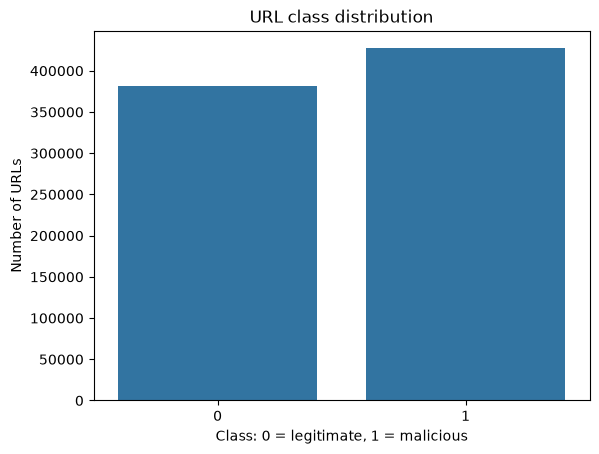

In [20]:
sns.countplot(
    data=df,
    x=TARGET_COLUMN
)

plt.title(
    "URL class distribution"
)

plt.xlabel(
    "Class: 0 = legitimate, 1 = malicious"
)

plt.ylabel(
    "Number of URLs"
)

plt.show()

In [21]:
X = df[FEATURE_COLUMNS].copy()
y = df[TARGET_COLUMN].copy()

X["has_suspicious_word"] = (
    X["has_suspicious_word"]
    .astype(int)
)

X = X.apply(
    pd.to_numeric,
    errors="coerce"
)

X = X.fillna(0)

print(
    f"Feature matrix shape: {X.shape}"
)

display(X.head())

Feature matrix shape: (808039, 17)


,url_length,num_digits,digit_ratio,special_char_ratio,num_hyphens,num_underscores,num_slashes,num_dots,num_question_marks,num_equals,num_at_symbols,num_percent,num_hashes,num_ampersands,num_subdomains,is_https,has_suspicious_word
0,39,7,0.179487,0.051282,0,0,0,2,0,0,0,0,0,0,0,0,0
1,36,6,0.166667,0.055556,0,0,0,2,0,0,0,0,0,0,0,0,0
2,12,5,0.416667,0.083333,0,0,0,1,0,0,0,0,0,0,0,0,0
3,35,4,0.114286,0.057143,0,0,0,2,0,0,0,0,0,0,0,0,0
4,20,5,0.250000,0.100000,0,0,0,2,0,0,0,0,0,0,0,0,0


In [22]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(
    f"Training rows: {len(X_train)}"
)

print(
    f"Testing rows: {len(X_test)}"
)

Training rows: 646431
Testing rows: 161608


In [23]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

random_forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

logistic_regression_model = Pipeline(
    steps=[
        (
            "scaler",
            StandardScaler()
        ),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

random_forest_model.fit(
    X_train,
    y_train
)

logistic_regression_model.fit(
    X_train,
    y_train
)

print("Both models were trained successfully.")

Both models were trained successfully.


In [24]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    f1_score,
    precision_score,
    recall_score
)

models = {
    "Random Forest": random_forest_model,
    "Logistic Regression": logistic_regression_model,
}

results = []

for model_name, model in models.items():
    predictions = model.predict(X_test)

    results.append(
        {
            "model": model_name,
            "accuracy": accuracy_score(
                y_test,
                predictions
            ),
            "precision": precision_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "recall": recall_score(
                y_test,
                predictions,
                zero_division=0
            ),
            "f1_score": f1_score(
                y_test,
                predictions,
                zero_division=0
            ),
        }
    )

    print(f"\n{model_name}")
    print(
        classification_report(
            y_test,
            predictions,
            target_names=[
                "legitimate",
                "malicious"
            ],
            zero_division=0
        )
    )

results_df = pd.DataFrame(results)

print("Model comparison:")
display(results_df)


Random Forest
              precision    recall  f1-score   support

  legitimate       0.92      0.88      0.90     76202
   malicious       0.90      0.93      0.91     85406

    accuracy                           0.91    161608
   macro avg       0.91      0.91      0.91    161608
weighted avg       0.91      0.91      0.91    161608


Logistic Regression
              precision    recall  f1-score   support

  legitimate       0.82      0.73      0.77     76202
   malicious       0.78      0.86      0.82     85406

    accuracy                           0.80    161608
   macro avg       0.80      0.79      0.80    161608
weighted avg       0.80      0.80      0.80    161608

Model comparison:


,model,accuracy,precision,recall,f1_score
0,Random Forest,0.907251,0.896738,0.931796,0.913931
1,Logistic Regression,0.798277,0.779628,0.861930,0.818716


In [26]:
best_model = random_forest_model

best_model_name = "Random Forest"

print(
    f"Selected model: {best_model_name}"
)

Selected model: Random Forest


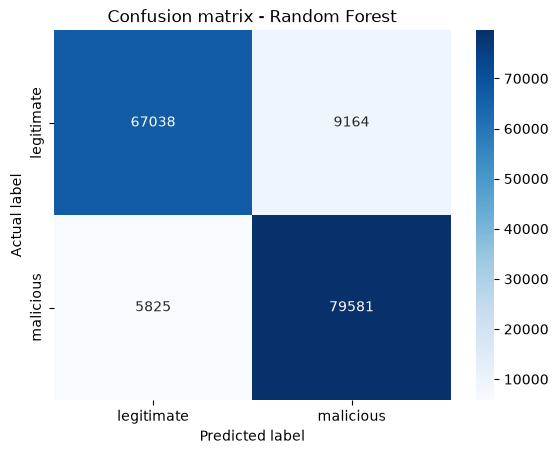

In [27]:
from sklearn.metrics import confusion_matrix

predictions = best_model.predict(X_test)

confusion = confusion_matrix(
    y_test,
    predictions
)

sns.heatmap(
    confusion,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=[
        "legitimate",
        "malicious"
    ],
    yticklabels=[
        "legitimate",
        "malicious"
    ]
)

plt.title(
    "Confusion matrix - Random Forest"
)

plt.xlabel("Predicted label")
plt.ylabel("Actual label")
plt.show()

,feature,importance
6,num_slashes,0.269745
15,is_https,0.115499
14,num_subdomains,0.092826
0,url_length,0.090969
3,special_char_ratio,0.087966
16,has_suspicious_word,0.063319
1,num_digits,0.060119
7,num_dots,0.060035
2,digit_ratio,0.053046
4,num_hyphens,0.048718


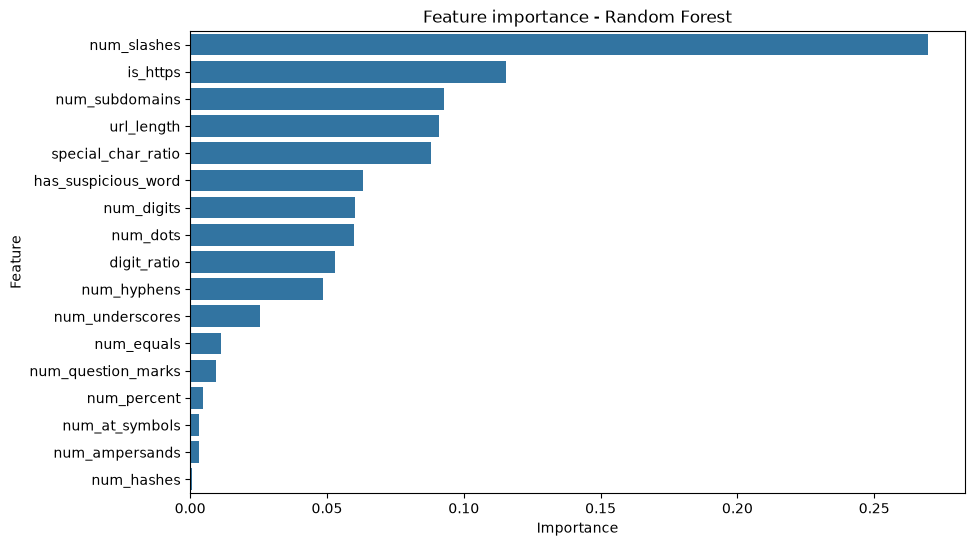

In [28]:
feature_importance = pd.DataFrame(
    {
        "feature": FEATURE_COLUMNS,
        "importance": (
            best_model
            .feature_importances_
        ),
    }
)

feature_importance = (
    feature_importance
    .sort_values(
        by="importance",
        ascending=False
    )
)

display(feature_importance)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=feature_importance,
    x="importance",
    y="feature"
)

plt.title(
    "Feature importance - Random Forest"
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.show()

In [29]:
import joblib

ARTIFACTS_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

MODEL_PATH = (
    ARTIFACTS_DIRECTORY
    / "url_model.joblib"
)

artifact = {
    "model": best_model,
    "feature_columns": FEATURE_COLUMNS,
    "url_column": URL_COLUMN,
    "target_column": TARGET_COLUMN,
    "label_mapping": {
        0: "legitimate",
        1: "malicious",
    },
}

joblib.dump(
    artifact,
    MODEL_PATH
)

print(
    f"Model saved to: {MODEL_PATH}"
)

Model saved to: c:\SafeFlowAI\team4_placeholder\ml\artifacts\url_model.joblib
